## NOVA Classification Modeling

Train and evaluate machine-learning models using nutrient features and food-name embeddings

## 1. Setup

In [2]:
import json, os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier)
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, confusion_matrix)

with open('data/config.json', encoding='utf-8') as f:
    CONFIG = json.load(f)

ID_COL = CONFIG['ID_COL']
TARGET = CONFIG['TARGET']
KO = CONFIG['KO']
TOKEN_COL = CONFIG['TOKEN_COL']
NUTRIENTS = CONFIG['nutrients']

RANDOM_STATE = 42
EMB_MODEL = 'KLUE-BERT'
EMB_DIR = 'embeddings'

In [3]:
def safe_name(value):
    return re.sub(r'[^0-9A-Za-z가-힣]+', '_', str(value)).strip('_')


tr = pd.read_csv('data/KNHANES_2024_train.csv', low_memory=False)
te = pd.read_csv('data/KNHANES_2024_test.csv', low_memory=False)

print(f'Training set: {len(tr):,}')
print(f'Test set: {len(te):,}')
print(f'Nutrient features: {len(NUTRIENTS)}')

print('\nNOVA class distribution')
print(pd.DataFrame({
    'Training': tr[TARGET].value_counts().sort_index(),
    'Test': te[TARGET].value_counts().sort_index(),
}).to_string())

Training set: 1,836
Test set: 460
Nutrient features: 55

NOVA class distribution
            Training  Test
NOVA 식품 분류                
1                744   186
2                 61    16
3                237    59
4                794   199


## 2. Text Features

In [4]:
def load_token_vectors(column, model_label):
    tokens = pd.read_csv(
        f'{EMB_DIR}/{safe_name(column)}__tokens.csv'
    )['token'].astype(str).tolist()

    vectors = np.load(
        f'{EMB_DIR}/{safe_name(column)}__{safe_name(model_label)}.npy'
    )
    return dict(zip(tokens, vectors)), vectors.shape[1]


def text_to_vector(series, token_map, dim):
    output = np.zeros((len(series), dim), dtype=np.float32)

    for i, text in enumerate(series):
        if pd.isna(text):
            continue

        vectors = [
            token_map[token]
            for token in str(text).split(',')
            if token in token_map
        ]

        if vectors:
            output[i] = np.mean(vectors, axis=0)

    return output


TOKEN_MAP, EMB_DIM = load_token_vectors(KO, EMB_MODEL)

M_tr = text_to_vector(tr[TOKEN_COL], TOKEN_MAP, EMB_DIM)
M_te = text_to_vector(te[TOKEN_COL], TOKEN_MAP, EMB_DIM)

print(f'{EMB_MODEL}: {len(TOKEN_MAP):,} tokens, {EMB_DIM} dimensions')
print('Training embeddings:', M_tr.shape)
print('Test embeddings:', M_te.shape)

KLUE-BERT: 2,368 tokens, 768 dimensions
Training embeddings: (1836, 768)
Test embeddings: (460, 768)


### PCA Explained Variance

PCA  5:  36.1% explained variance
PCA 10:  48.7% explained variance
PCA 20:  61.7% explained variance
PCA 50:  79.0% explained variance


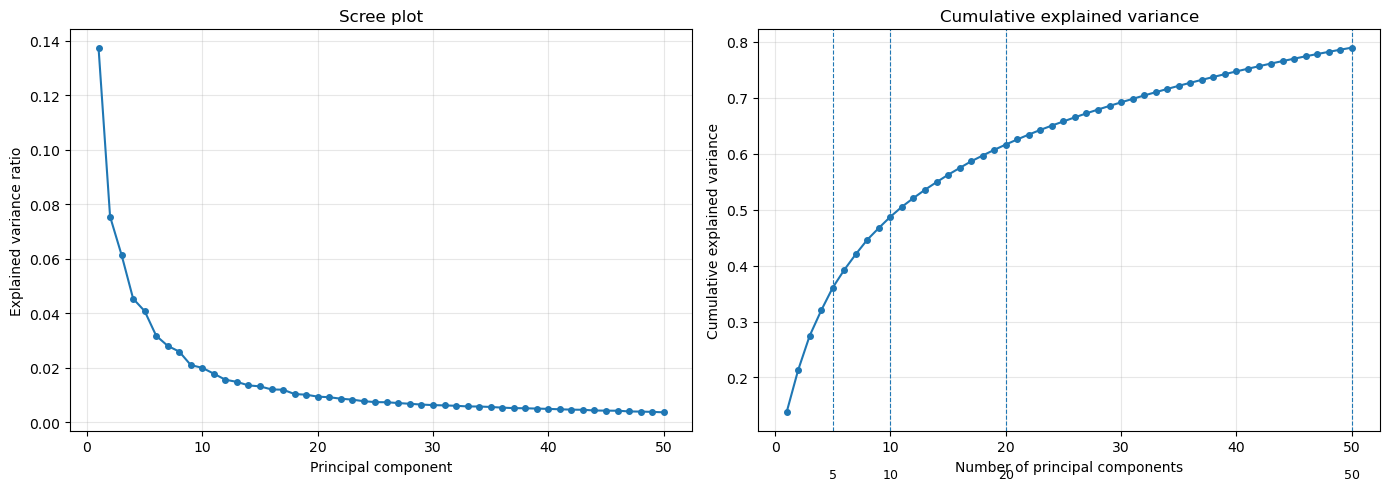

In [5]:
pca_check = PCA(n_components=50, random_state=RANDOM_STATE).fit(M_tr)
ratio = pca_check.explained_variance_ratio_

for k in [5, 10, 20, 50]:
    print(f'PCA {k:2d}: {ratio[:k].sum() * 100:5.1f}% explained variance')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, 51), ratio, marker='o', markersize=4)
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('Explained variance ratio')
axes[0].set_title('Scree plot')
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, 51), np.cumsum(ratio), marker='o', markersize=4)
for k in [5, 10, 20, 50]:
    axes[1].axvline(k, linestyle='--', linewidth=0.8)
    axes[1].text(k, 0.02, str(k), ha='center', fontsize=9)

axes[1].set_xlabel('Number of principal components')
axes[1].set_ylabel('Cumulative explained variance')
axes[1].set_title('Cumulative explained variance')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Classification Models

In [6]:
VARIANTS = {
    'baseline model': [],
    'text model': [KO],
}

PCA_LIST = [5, 10, 20, 50]


def get_models(subset=None):
    models = {
        'SVM': SVC(probability=True, class_weight='balanced', random_state=RANDOM_STATE),
        'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
        'Extra Trees': ExtraTreesClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
        'LightGBM': LGBMClassifier(objective='multiclass', class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1),
        'XGBoost': XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', random_state=RANDOM_STATE, n_jobs=-1),
        'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
        'AdaBoost': AdaBoostClassifier(random_state=RANDOM_STATE),
        'MLP': MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, early_stopping=True, random_state=RANDOM_STATE),
        'Balanced Random Forest': BalancedRandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    }

    if subset is None:
        return models

    return {name: models[name] for name in subset}

## 4. Cross-Validation

In [7]:
def cv_evaluate(text_cols, n_pca, subset=None, n_splits=5):
    X_nut = tr[NUTRIENTS].values
    y = tr[TARGET].values

    le = LabelEncoder()
    y_enc = le.fit_transform(y)

    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    metrics = ['f1', 'mcc', 'acc', 'prec', 'rec']
    fold_scores = {
        name: {metric: [] for metric in metrics}
        for name in get_models(subset)
    }

    for tr_idx, va_idx in skf.split(X_nut, y_enc):
        Xtr_parts = [X_nut[tr_idx]]
        Xva_parts = [X_nut[va_idx]]

        # Add PCA-reduced text embeddings
        if text_cols:
            k = min(n_pca, len(tr_idx), EMB_DIM)
            pca = PCA(n_components=k, random_state=RANDOM_STATE)
            Xtr_parts.append(pca.fit_transform(M_tr[tr_idx]))
            Xva_parts.append(pca.transform(M_tr[va_idx]))

        scaler = StandardScaler()
        Xtr = scaler.fit_transform(np.hstack(Xtr_parts))
        Xva = scaler.transform(np.hstack(Xva_parts))

        for name, model in get_models(subset).items():
            model.fit(Xtr, y_enc[tr_idx])
            pred = model.predict(Xva)

            fold_scores[name]['f1'].append(f1_score(y_enc[va_idx], pred, average='macro', zero_division=0))
            fold_scores[name]['mcc'].append(matthews_corrcoef(y_enc[va_idx], pred))
            fold_scores[name]['acc'].append(accuracy_score(y_enc[va_idx], pred))
            fold_scores[name]['prec'].append(precision_score(y_enc[va_idx], pred, average='macro', zero_division=0))
            fold_scores[name]['rec'].append(recall_score(y_enc[va_idx], pred, average='macro', zero_division=0)
            )

    rows = []
    for name, scores in fold_scores.items():
        rows.append({
            'Model': name,
            'Accuracy': np.mean(scores['acc']),
            'Macro Precision': np.mean(scores['prec']),
            'Macro Recall': np.mean(scores['rec']),
            'MCC': np.mean(scores['mcc']),
            'Macro F1-score': np.mean(scores['f1']),
        })

    return (pd.DataFrame(rows).sort_values('Macro F1-score', ascending=False).reset_index(drop=True))

In [8]:
cv_results = {}

for variant, text_cols in VARIANTS.items():
    pca_options = [None] if not text_cols else PCA_LIST

    for n_pca in pca_options:
        start = time.time()
        result = cv_evaluate(text_cols, n_pca or 0)
        cv_results[(variant, n_pca)] = result

        best = result.iloc[0]
        label = f'PCA {n_pca}' if n_pca else '-'

        print(
            f'{variant} | {label} | {best["Model"]} | '
            f'F1={best["Macro F1-score"]:.4f} | '
            f'{time.time() - start:.0f}s'
        )

baseline model | - | LightGBM | F1=0.8661 | 32s
text model | PCA 5 | LightGBM | F1=0.8853 | 35s
text model | PCA 10 | LightGBM | F1=0.8889 | 37s
text model | PCA 20 | LightGBM | F1=0.8891 | 43s
text model | PCA 50 | LightGBM | F1=0.8875 | 61s


### Cross-Validation Summary

In [9]:
rows = []

for (variant, n_pca), result in cv_results.items():
    best = result.iloc[0]
    rows.append([
        variant,
        n_pca if n_pca else '-',
        best['Model'],
        best['Accuracy'],
        best['MCC'],
        best['Macro F1-score'],
    ])

cv_summary = pd.DataFrame(rows, columns=['model', 'PCA', 'best classifier', 'Accuracy', 'MCC', 'Macro F1-score'])
cv_summary = (cv_summary.sort_values('Macro F1-score', ascending=False).reset_index(drop=True))
cv_summary.round(4)

,model,PCA,best classifier,Accuracy,MCC,Macro F1-score
0,text model,20,LightGBM,0.9188,0.8710,0.8891
1,text model,10,LightGBM,0.9188,0.8712,0.8889
2,text model,50,LightGBM,0.9216,0.8751,0.8875
3,text model,5,LightGBM,0.9150,0.8648,0.8853
4,baseline model,-,LightGBM,0.9047,0.8484,0.8661


In [10]:
for (variant, n_pca), result in cv_results.items():
    label = f'{variant} (PCA {n_pca})' if n_pca else variant

    table = (
        result
        .set_index('Model')[['Accuracy', 'Macro Precision', 'Macro Recall', 'MCC', 'Macro F1-score']]
        .round(4)
        .sort_values('Macro F1-score', ascending=False)
    )

    print(f'\n{label}')
    display(table)


baseline model


,Accuracy,Macro Precision,Macro Recall,MCC,Macro F1-score
Model,,,,,
LightGBM,0.9047,0.8764,0.8583,0.8484,0.8661
Extra Trees,0.8927,0.8921,0.8205,0.8289,0.8470
XGBoost,0.8927,0.8753,0.8232,0.8285,0.8445
Gradient Boosting,0.8894,0.8743,0.8214,0.8233,0.8423
Random Forest,0.8845,0.8853,0.7908,0.8151,0.8261
Balanced Random Forest,0.8410,0.7365,0.8458,0.7607,0.7721
Decision Tree,0.8192,0.7570,0.7561,0.7136,0.7556
MLP,0.8083,0.8068,0.6494,0.6892,0.6801
SVM,0.7146,0.6209,0.6843,0.5852,0.6311



text model (PCA 5)


,Accuracy,Macro Precision,Macro Recall,MCC,Macro F1-score
Model,,,,,
LightGBM,0.9150,0.8994,0.8751,0.8648,0.8853
XGBoost,0.9101,0.8933,0.8649,0.8569,0.8766
Extra Trees,0.9025,0.9122,0.8493,0.8444,0.8739
Gradient Boosting,0.8960,0.8911,0.8151,0.8336,0.8462
Random Forest,0.8927,0.9067,0.7996,0.8284,0.8383
Balanced Random Forest,0.8540,0.7551,0.8558,0.7791,0.7895
MLP,0.8426,0.8077,0.7103,0.7470,0.7457
Decision Tree,0.8110,0.7468,0.7226,0.7003,0.7323
SVM,0.7908,0.6757,0.7671,0.6828,0.7042



text model (PCA 10)


,Accuracy,Macro Precision,Macro Recall,MCC,Macro F1-score
Model,,,,,
LightGBM,0.9188,0.8987,0.8839,0.8712,0.8889
XGBoost,0.9134,0.8938,0.8604,0.8621,0.8741
Extra Trees,0.9014,0.9156,0.8467,0.8427,0.8731
Random Forest,0.9036,0.9167,0.8298,0.8461,0.8638
Gradient Boosting,0.8976,0.8965,0.8042,0.8361,0.8405
Balanced Random Forest,0.8584,0.7593,0.8647,0.7861,0.7950
MLP,0.8584,0.8353,0.7435,0.7731,0.7774
SVM,0.8333,0.7456,0.8040,0.7446,0.7679
Decision Tree,0.8154,0.7327,0.7404,0.7080,0.7329



text model (PCA 20)


,Accuracy,Macro Precision,Macro Recall,MCC,Macro F1-score
Model,,,,,
LightGBM,0.9188,0.9016,0.8802,0.8710,0.8891
XGBoost,0.9161,0.8967,0.8640,0.8664,0.8778
Extra Trees,0.8976,0.9186,0.8323,0.8368,0.8642
Random Forest,0.8916,0.9083,0.7927,0.8266,0.8346
Gradient Boosting,0.8971,0.8807,0.7988,0.8353,0.8315
Balanced Random Forest,0.8584,0.7628,0.8553,0.7849,0.7959
SVM,0.8508,0.7821,0.8149,0.7693,0.7950
MLP,0.8638,0.8317,0.7546,0.7819,0.7839
Decision Tree,0.8066,0.7265,0.7238,0.6931,0.7232



text model (PCA 50)


,Accuracy,Macro Precision,Macro Recall,MCC,Macro F1-score
Model,,,,,
LightGBM,0.9216,0.9135,0.8685,0.8751,0.8875
XGBoost,0.9101,0.8949,0.8386,0.8567,0.8622
Extra Trees,0.8922,0.9247,0.8126,0.8287,0.8499
SVM,0.8753,0.8549,0.8278,0.8047,0.8371
Gradient Boosting,0.8943,0.8890,0.7829,0.8309,0.8227
Random Forest,0.8845,0.9066,0.7681,0.8157,0.8156
MLP,0.8698,0.8698,0.7676,0.7916,0.8028
Balanced Random Forest,0.8540,0.7575,0.8616,0.7794,0.7925
Decision Tree,0.8165,0.7397,0.7226,0.7078,0.7292


## 5. Final Model

In [11]:
FINAL_VARIANT = 'text model'
FINAL_PCA = 20
FINAL_MODEL_NAME = 'LightGBM'

selected_cv = cv_results[(FINAL_VARIANT, FINAL_PCA)]
selected_row = selected_cv[
    selected_cv['Model'] == FINAL_MODEL_NAME
].iloc[0]

print('Final model')
print(f'  Variant: {FINAL_VARIANT}')
print(f'  PCA components: {FINAL_PCA}')
print(f'  Classifier: {FINAL_MODEL_NAME}')
print(f'  Cross-validated macro F1: 'f'{selected_row["Macro F1-score"]:.4f}')

Final model
  Variant: text model
  PCA components: 20
  Classifier: LightGBM
  Cross-validated macro F1: 0.8891


In [12]:
le_final = LabelEncoder()
y_tr_enc = le_final.fit_transform(tr[TARGET].values)
y_te_enc = le_final.transform(te[TARGET].values)

Xtr_parts = [tr[NUTRIENTS].values]
Xte_parts = [te[NUTRIENTS].values]

# Add text principal components
pca_final = PCA(n_components=FINAL_PCA, random_state=RANDOM_STATE)
Xtr_parts.append(pca_final.fit_transform(M_tr))
Xte_parts.append(pca_final.transform(M_te))

sc_final = StandardScaler()
X_tr_final = sc_final.fit_transform(np.hstack(Xtr_parts))
X_te_final = sc_final.transform(np.hstack(Xte_parts))

final_model = get_models([FINAL_MODEL_NAME])[FINAL_MODEL_NAME]
final_model.fit(X_tr_final, y_tr_enc)

print('Training matrix:', X_tr_final.shape)
print('Test matrix:', X_te_final.shape)

Training matrix: (1836, 75)
Test matrix: (460, 75)


## 6. Test Evaluation

In [13]:
pred_enc = final_model.predict(X_te_final)
pred_label = le_final.inverse_transform(pred_enc)
true_label = te[TARGET].values

test_metrics = {
    'Accuracy': accuracy_score(y_te_enc, pred_enc),
    'Macro Precision': precision_score(y_te_enc, pred_enc, average='macro', zero_division=0),
    'Macro Recall': recall_score(y_te_enc, pred_enc, average='macro', zero_division=0),
    'MCC': matthews_corrcoef(y_te_enc, pred_enc),
    'Macro F1-score': f1_score(y_te_enc, pred_enc, average='macro', zero_division=0),

}

for metric, value in test_metrics.items():
    print(f'{metric}: {value:.4f}')

Accuracy: 0.9478
Macro Precision: 0.9350
Macro Recall: 0.9133
MCC: 0.9174
Macro F1-score: 0.9211


### Confusion Matrix

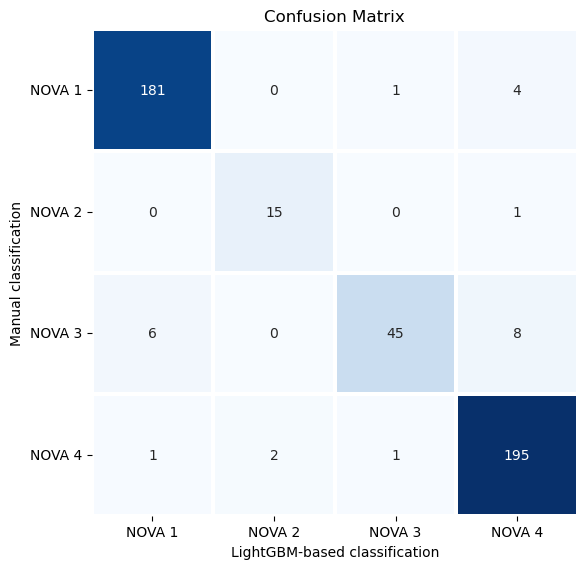

In [14]:
labels_sorted = sorted(le_final.classes_)

cm = confusion_matrix(true_label, pred_label, labels=labels_sorted)
cm_df = pd.DataFrame(cm, index=[f'NOVA {label}' for label in labels_sorted], columns=[f'NOVA {label}' for label in labels_sorted])

plt.figure(figsize=(6.6, 5.8))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False, square=True, linewidths=1.5)

plt.title('Confusion Matrix')
plt.xlabel('LightGBM-based classification')
plt.ylabel('Manual classification')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. SHAP Analysis
- Feature importance is examined using the nutrient-only LightGBM baseline model

In [15]:
import shap

X_tr_base = tr[NUTRIENTS].values
X_te_base = te[NUTRIENTS].values

sc_base = StandardScaler()
X_tr_base = sc_base.fit_transform(X_tr_base)
X_te_base = sc_base.transform(X_te_base)

model_base = get_models(['LightGBM'])['LightGBM']
model_base.fit(X_tr_base, y_tr_enc)

explainer = shap.TreeExplainer(model_base)
raw_shap = explainer.shap_values(X_te_base)

# Convert SHAP output to (samples, features, classes)
if isinstance(raw_shap, list):
    shap_values = np.stack(raw_shap, axis=-1)
else:
    shap_values = np.asarray(raw_shap)
    if shap_values.ndim == 2:
        shap_values = shap_values[:, :, np.newaxis]

print('SHAP values:', shap_values.shape)

SHAP values: (460, 55, 4)


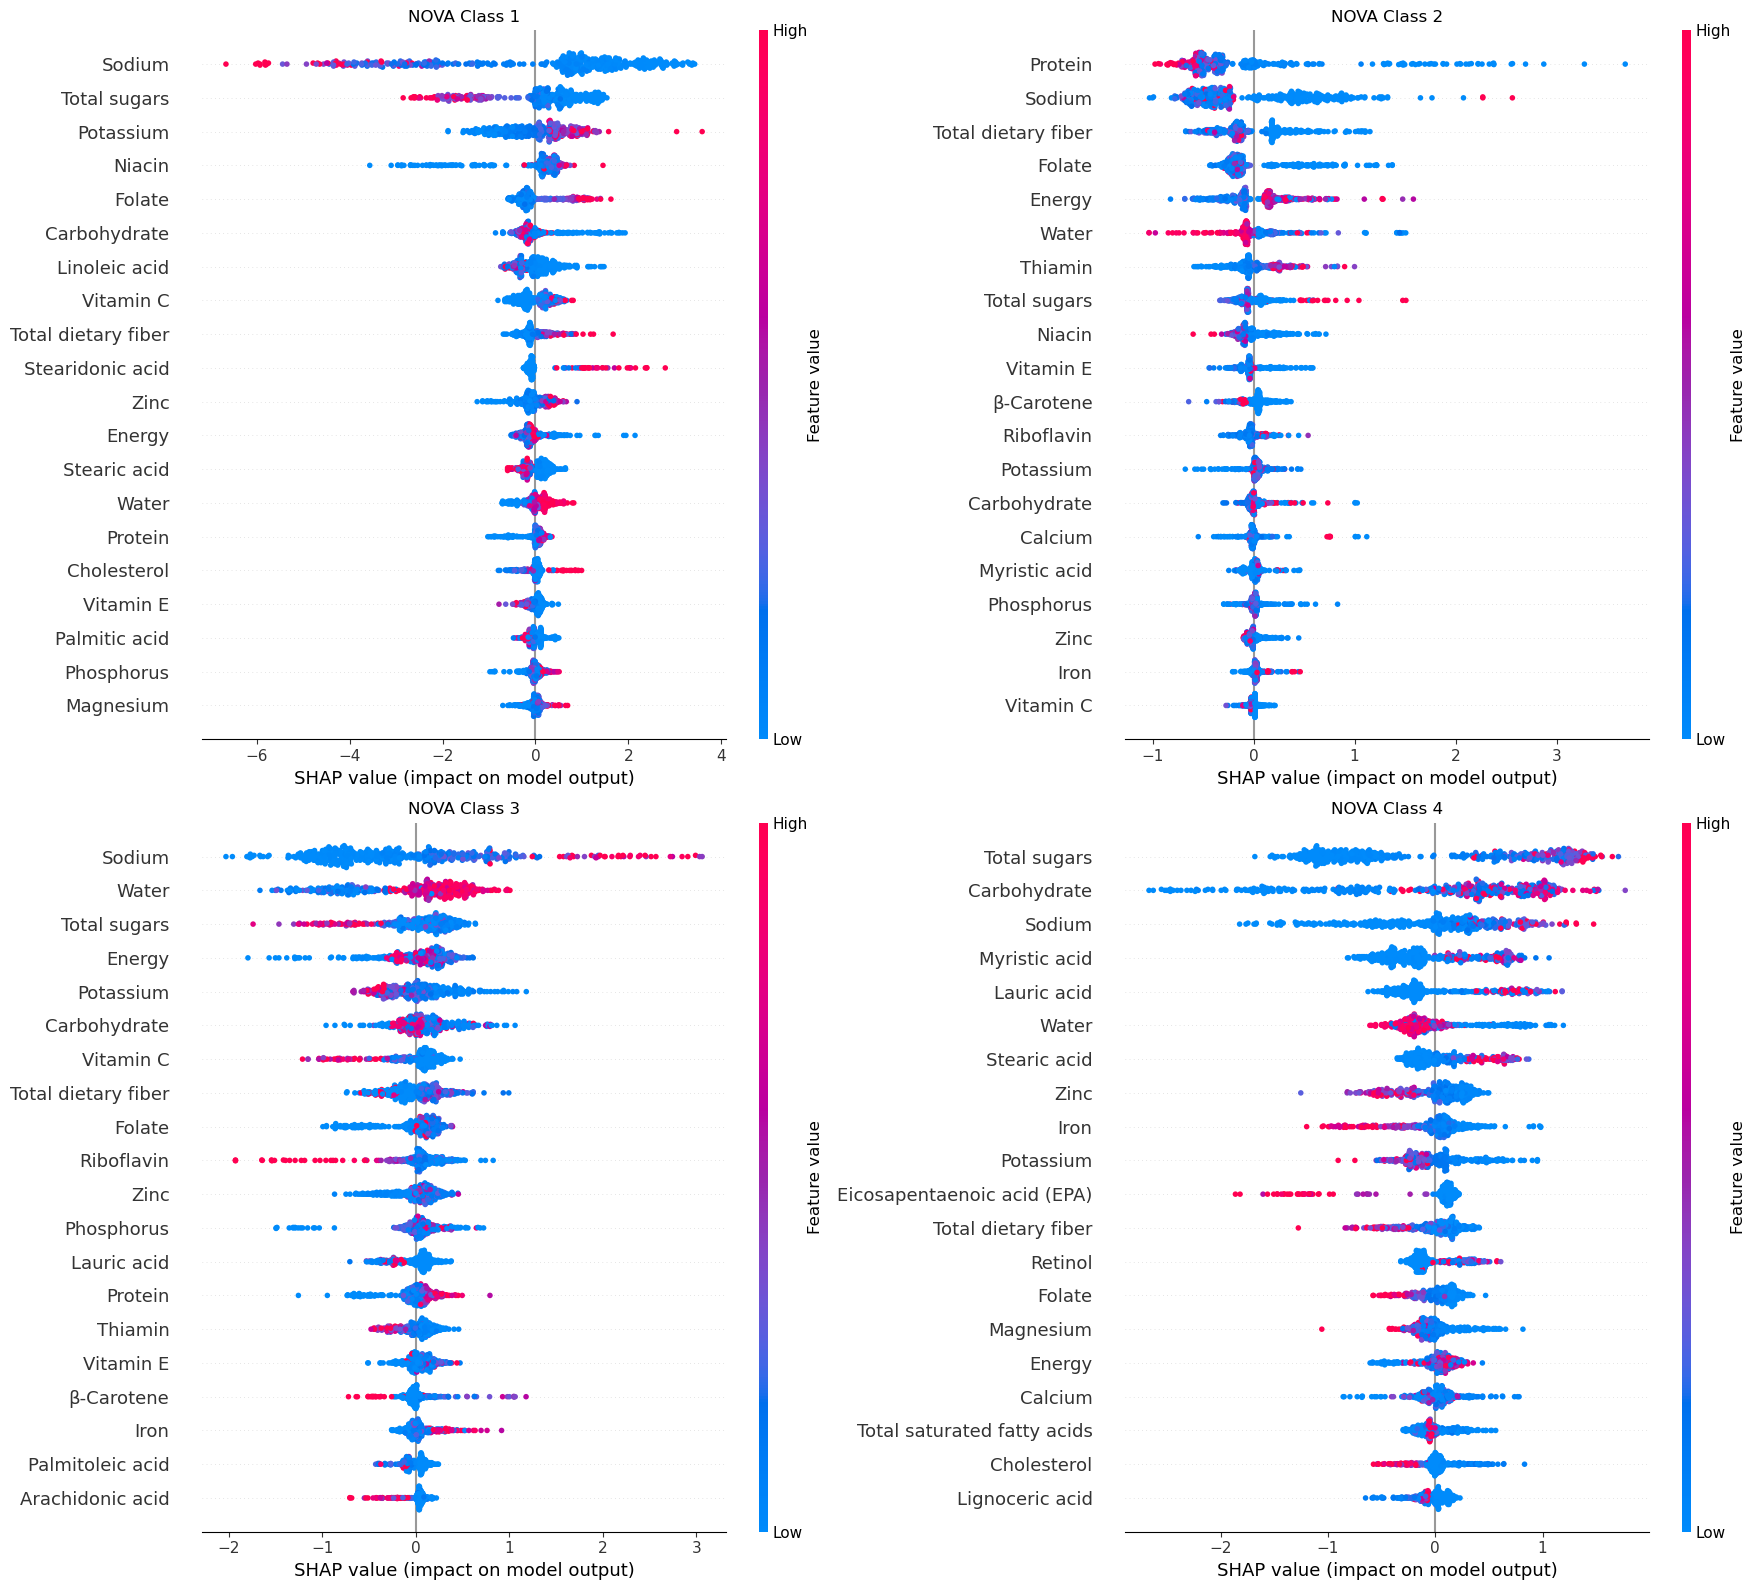

In [16]:
max_display = 20
class_labels = le_final.classes_

fig, axes = plt.subplots(2, 2, figsize=(18, 16))
axes = axes.flatten()

for i, class_label in enumerate(class_labels):
    plt.sca(axes[i])

    shap.summary_plot(
        shap_values[:, :, i],
        X_te_base,
        feature_names=NUTRIENTS,
        max_display=max_display,
        show=False,
        plot_size=None,
    )

    axes[i].set_title(f'NOVA Class {int(class_label)}')

plt.tight_layout()
plt.show()